- Authors: Furkan Cantürk & Gemini 3 Pro
- Date: 21.11.2025

# Module 2: Advanced Regression & Hyperparameter Optimization

## 1. Problem Statement: Ames Housing Price Prediction

**The Goal:** Predict the final sale price of a home based on 79 explanatory variables describing (almost) every aspect of residential homes in Ames, Iowa.

**Why this is harder than Module 1:**
1.  **Regression:** We are predicting a continuous value, not a class.
2.  **High Dimensionality:** There are many more features (categorical and numerical).
3.  **Production Standards:** We will stop writing "scripty" code and start writing **reusable training pipelines** with experiment tracking using `mlflow`.

**Models Covered:**
* **Linear Regression:** The baseline.
* **Decision Tree:** To see overfitting in action.
* **XGBoost / LightGBM:** The gradient boosting standards.
* **CatBoost:** Special handling for categorical features.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

## 2. Data Loading & Basic EDA

We use the **Ames Housing** dataset. 

Loading Ames Housing dataset...
Dataset Shape: (1460, 81)


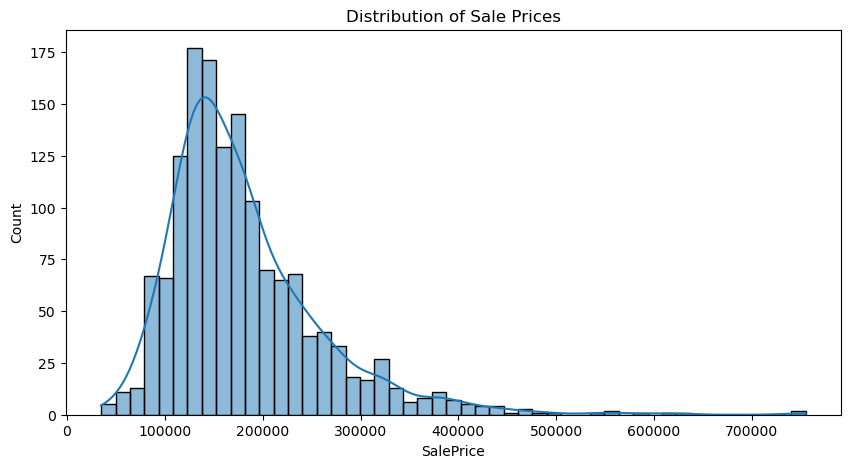

Top 5 Features correlated with SalePrice:
SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64


In [ ]:
print("Loading Ames Housing dataset...")
# version 1 is the standard Ames Housing dataset on OpenML
housing = fetch_openml(name="house_prices", as_frame=True, parser='auto')
df = housing.frame

print(f"Dataset Shape: {df.shape}")

# Target variable is 'SalePrice'
target_col = 'SalePrice'

# Quick EDA
plt.figure(figsize=(10, 5))
sns.histplot(df[target_col], kde=True)
plt.title("Distribution of Sale Prices")
plt.show()

# Check correlation of numerical features with SalePrice
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr()
print("Top 5 Features correlated with SalePrice:")
print(corr['SalePrice'].sort_values(ascending=False).head(6))

## 3. Preprocessing Strategy

We have two distinct strategies for handling data, depending on the model:

1.  **Strategy A (Linear, XGBoost, LightGBM, Decision Tree):**
    * **Categoricals:** Must be converted to numbers. We use **One-Hot Encoding**.
    * **Numerics:** Must be **Scaled** (StandardScaler) for Linear Regression.

2.  **Strategy B (CatBoost):**
    * **Categoricals:** CatBoost handles these natively. We just need to fill missing values and ensure they are strings/integers, but we **DO NOT** One-Hot encode them. This preserves information and reduces dimensionality.
    * **Numerics:** Scaling is optional for trees, but we'll keep it consistent.

In [ ]:
# Drop ID if exists (it's not a predictor)
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

X = df.drop(columns=[target_col])
y = df[target_col]

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Identify columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(include=['number']).columns.tolist()

# --- PIPELINE FACTORY ---
# Instead of hardcoding one pipeline, we make a function that returns the right one.

def get_pipeline(model_type, model_obj):
    """
    Constructs a pipeline tailored to the model type.
    """
    
    # 1. Numerical Preprocessing (Always the same)
    # Impute missing with median, then scale.
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    
    # 2. Categorical Preprocessing (Depends on model)
    if model_type == 'catboost':
        # CatBoost Strategy: Just fill missing values. 
        # CatBoostRegressor requires us to pass categorical indices later, 
        # or we can use OrdinalEncoder to turn strings into integers.
        # Here, we use OrdinalEncoder with handling for unknown categories
        cat_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ])
    else:
        # Standard Strategy: One-Hot Encoding
        cat_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])
        
    # Combine
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_cols),
            ('cat', cat_transformer, cat_cols)
        ]
    )
    
    # Create final pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model_obj)
    ])
    
    return pipeline

print("Pipeline Factory defined.")

Pipeline Factory defined.


## 4. Hyperparameter Optimization (HPO) Engine

We will build a function `run_experiment` that:
1.  Takes a model and a hyperparameter grid.
2.  Runs `GridSearchCV`.
3.  **Logs everything to MLflow**.
4.  Returns the best model and metrics.

**Note on Overfitting vs Underfitting:**
* **Underfitting:** Model is too simple (Linear Regression). High bias. Poor train AND val score.
* **Overfitting:** Model is too complex (Decision Tree with no depth limit). Low bias, High variance. Great train score, poor val score.
* **HPO Goal:** Find the "Goldilocks" zone.

In [ ]:
# Set output container
experiment_results = []

def setup_mlflow_experiment():
    """
    Setup MLflow tracking and handle deleted experiments.
    This should be called once before running experiments.
    """
    # Set tracking URI to SQLite database for persistent logging
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    
    experiment_name = "Ames_Housing_Regression"
    
    # Check if experiment exists and is deleted
    experiment = mlflow.get_experiment_by_name(experiment_name)
    
    if experiment is not None and experiment.lifecycle_stage == "deleted":
        print(f"⚠️  Experiment '{experiment_name}' is deleted. Recreating with fresh state...")
        try:
            from sqlalchemy import create_engine, text
            
            # Access the database directly
            db_path = "sqlite:///mlflow.db"
            engine = create_engine(db_path)
            with engine.connect() as conn:
                # Update the lifecycle_stage to 'active'
                conn.execute(text(f"UPDATE experiments SET lifecycle_stage='active' WHERE name='{experiment_name}'"))
                conn.commit()
            print(f"✅ Experiment state reset successfully!")
        except Exception as e:
            print(f"Alternative approach: Using new experiment ID...")
            # If database update fails, just create a new experiment with timestamp
            import time
            timestamp = int(time.time())
            experiment_name = f"Ames_Housing_Regression_{timestamp}"
            print(f"Using experiment: {experiment_name}")
    
    # Set or create experiment
    mlflow.set_experiment(experiment_name)
    print(f"✅ MLflow experiment '{experiment_name}' is ready!")

def run_experiment(name, model_obj, param_grid):
    print(f"--- Running Experiment: {name} ---")
    
    # 1. Build Pipeline
    pipeline = get_pipeline(name, model_obj) 
    
    # 2. Setup Grid Search
    # We rename params to match pipeline structure: "model__param_name"
    pipeline_params = {f"model__{k}": v for k, v in param_grid.items()}
    
    cv = KFold(n_splits=3, shuffle=True, random_state=42)
    
    grid_search = GridSearchCV(
        pipeline, 
        pipeline_params, 
        cv=cv, 
        scoring='neg_root_mean_squared_error', # Scikit-learn uses negative error for maximization
        return_train_score=True,
        verbose=1,
        n_jobs=-1
    )
    
    with mlflow.start_run(run_name=name):
        # Fit the grid
        grid_search.fit(X_train, y_train)
        
        # Log all HPO iterations to parent run with model-specific metric names
        # This creates line charts with consistent colors per model
        for idx, params in enumerate(grid_search.cv_results_['params']):
            # Extract cross-validation scores
            cv_rmse = -grid_search.cv_results_['mean_test_score'][idx]
            cv_rmse_std = grid_search.cv_results_['std_test_score'][idx]
            train_rmse = -grid_search.cv_results_['mean_train_score'][idx]
            
            # Log metrics with step parameter to create line charts
            # Use model name in metric name so each model gets its own color
            mlflow.log_metric(f"{name}/cv_rmse_mean", cv_rmse, step=idx)
            mlflow.log_metric(f"{name}/cv_rmse_std", cv_rmse_std, step=idx)
            mlflow.log_metric(f"{name}/train_rmse_mean", train_rmse, step=idx)
        
        # Get bests
        best_model = grid_search.best_estimator_
        best_params = grid_search.best_params_
        best_cv_score = -grid_search.best_score_ # Convert back to positive RMSE
        
        # Evaluate on Test Set (Hold-out)
        y_pred = best_model.predict(X_test)
        test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        test_r2 = r2_score(y_test, y_pred)
        
        # Log best model metrics to parent run
        mlflow.log_params(best_params)
        mlflow.log_metric("best_cv_rmse", best_cv_score)
        mlflow.log_metric("test_rmse", test_rmse)
        mlflow.log_metric("test_r2", test_r2)
        
        # Log the model itself (optional, can be large)
        # mlflow.sklearn.log_model(best_model, "model")
        
        print(f"Best CV RMSE: {best_cv_score:.0f}")
        print(f"Test RMSE: {test_rmse:.0f}")
        print(f"Best Params: {best_params}\n")
        
        return {
            "Model": name,
            "Best CV RMSE": best_cv_score,
            "Test RMSE": test_rmse,
            "Test R2": test_r2,
            "Best Params": best_params
        }

## 5. Execution Loop

Defining the search spaces. We use small grids for demonstration speed.

In [ ]:
# Setup MLflow experiment (handles deleted experiments, creates active experiment)
setup_mlflow_experiment()

# 1. Linear Regression (Baseline - No HPO needed really, but good for consistency)
# fit_intercept is standard
models_config = [
    {
        "name": "linear_regression",
        "model": LinearRegression(),
        "params": {} 
    },
    {
        "name": "decision_tree",
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            "max_depth": [5, 10, None],  # None = potential overfitting
            "min_samples_leaf": [1, 5, 10]
        }
    },
    {
        "name": "xgboost",
        "model": xgb.XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1, verbosity=0),
        "params": {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5]
        }
    },
    {
        "name": "lightgbm",
        "model": lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1),
        "params": {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "num_leaves": [31, 50]
        }
    },
    {
        "name": "catboost",
        "model": CatBoostRegressor(random_state=42, verbose=0, thread_count=-1, allow_writing_files=False),
        "params": {
            "iterations": [50, 100, 200, 150],
            "learning_rate": [0.05, 0.1],
            "depth": [4, 6]
        }
    }
]

# Run the loop
results = []
for config in models_config:
    res = run_experiment(config["name"], config["model"], config["params"])
    results.append(res)

✅ MLflow experiment 'Ames_Housing_Regression' is ready!
--- Running Experiment: linear_regression ---
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Best CV RMSE: 37680
Test RMSE: 29447
Best Params: {}

--- Running Experiment: decision_tree ---
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best CV RMSE: 37680
Test RMSE: 29447
Best Params: {}

--- Running Experiment: decision_tree ---
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best CV RMSE: 39921
Test RMSE: 38992
Best Params: {'model__max_depth': 10, 'model__min_samples_leaf': 10}

--- Running Experiment: xgboost ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV RMSE: 39921
Test RMSE: 38992
Best Params: {'model__max_depth': 10, 'model__min_samples_leaf': 10}

--- Running Experiment: xgboost ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV RMSE: 28691
Test RMSE: 25661
Best Params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimato

c:\Users\Asus\miniconda3\envs\ml_crash_course\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Best CV RMSE: 29013
Test RMSE: 30641
Best Params: {'model__learning_rate': 0.05, 'model__n_estimators': 100, 'model__num_leaves': 31}

--- Running Experiment: catboost ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV RMSE: 26948
Test RMSE: 27206
Best Params: {'model__depth': 6, 'model__iterations': 200, 'model__learning_rate': 0.1}

Best CV RMSE: 26948
Test RMSE: 27206
Best Params: {'model__depth': 6, 'model__iterations': 200, 'model__learning_rate': 0.1}



## 6. Final Analysis

Let's view the leaderboard.


--- FINAL LEADERBOARD ---
               Model     Test RMSE   Test R2  \
2            xgboost  25661.329038  0.914149   
4           catboost  27206.486359  0.903499   
0  linear_regression  29447.295376  0.886948   
3           lightgbm  30640.754619  0.877599   
1      decision_tree  38991.753941  0.801787   

                                                                           Best Params  
2     {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}  
4           {'model__depth': 6, 'model__iterations': 200, 'model__learning_rate': 0.1}  
0                                                                                   {}  
3  {'model__learning_rate': 0.05, 'model__n_estimators': 100, 'model__num_leaves': 31}  
1                              {'model__max_depth': 10, 'model__min_samples_leaf': 10}  


C:\Users\Asus\AppData\Local\Temp\ipykernel_2352\3557324757.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='Test R2', palette='viridis')


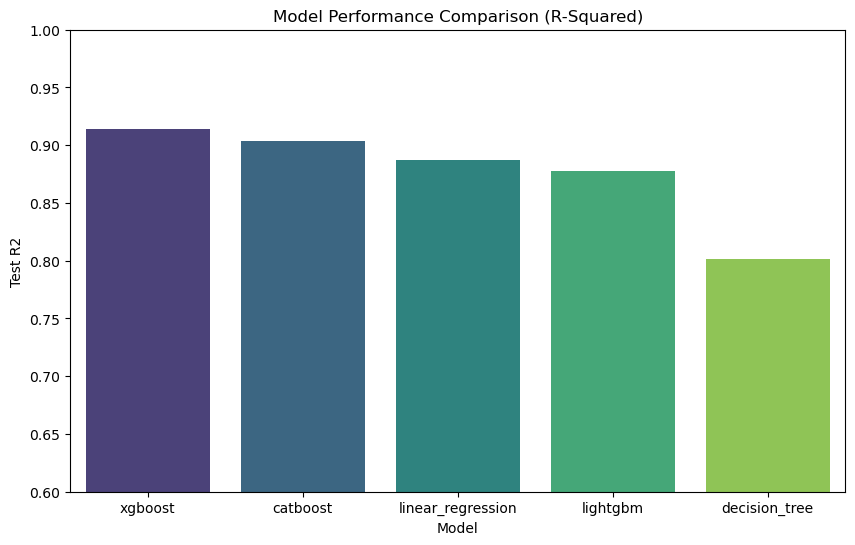

In [ ]:
results_df = pd.DataFrame(results).sort_values(by="Test RMSE")

print("\n--- FINAL LEADERBOARD ---")
# Formatting for cleaner output
pd.set_option('display.max_colwidth', 100)
print(results_df[['Model', 'Test RMSE', 'Test R2', 'Best Params']])

# Visualization of R2 Scores
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x='Model', y='Test R2', palette='viridis')
plt.title("Model Performance Comparison (R-Squared)")
plt.ylim(0.6, 1.0) # Zoom in on the top
plt.show()

## 7. Discussion: Overfitting vs Underfitting

Look at the **Decision Tree** results in your loop output.

* **Scenario:** If `max_depth` selected was `None` and `min_samples_leaf` was 1, the tree likely memorized the training data.
* **Observation:** You might see a very low Training Error (if you inspected it) but a much higher CV/Test Error compared to XGBoost.

**Why Gradient Boosting (XGB/LGBM/Cat) Wins:**
Instead of building one massive, overfit tree, these algorithms build hundreds of **shallow, weak trees** (high bias individually) and sum them up to reduce bias without increasing variance as much as a single deep tree.

**Why CatBoost is Special:**
Did you notice we didn't One-Hot Encode for CatBoost?
* **One-Hot:** Turns 1 categorical column "Neighborhood" (25 values) into 25 separate columns. This makes the data "sparse" and hard for trees to split efficiently.
* **CatBoost:** Keeps "Neighborhood" as 1 column and uses statistics (Target Encoding) to calculate the split. This is often more accurate and faster for high-cardinality data.